# Hillstrom Email Campaign: Exploratory Data Analysis & Uplift Modeling Prep

In this notebook, I explore the Kevin Hillstrom MineThatData dataset to validate data quality, verify that the randomized experiment was balanced, and look for heterogeneous treatment effects before building an uplift modeling pipeline.

My main goals here:
1. Inspect the raw records for missing values and clean up any formatting issues.
2. Confirm covariate balance between the treated and control cohorts using standardized mean differences.
3. Calculate the overall average treatment effect (ATE) and test whether the lift is statistically significant.
4. Analyze how treatment response differs across customer segments to motivate individual-level uplift modeling.


In [1]:
import os
import warnings
warnings.filterwarnings("ignore")

# Keep relative paths working whether I run from the project root or the notebooks folder
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from scipy import stats

%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "figure.figsize": (11, 5)})
sns.set_theme(style="whitegrid", palette="muted", font_scale=1.0)

FIG_DIR = "notebooks/figures"
os.makedirs(FIG_DIR, exist_ok=True)


## 1. Data Ingestion, Health Checks, and Preprocessing

I start by loading the CSV, standardizing column names to snake_case, and checking for missing values or unexpected category labels.


In [2]:
df_raw = pd.read_csv("data/minethatdata.csv")
df_raw.columns = df_raw.columns.str.strip().str.lower().str.replace(" ", "_")

print(f"Dataset shape: {df_raw.shape[0]:,} rows by {df_raw.shape[1]} columns")
print("\nMissing value count per column:")
print(df_raw.isnull().sum().to_frame("missing").T)

df_raw.head()


Dataset shape: 64,000 rows by 12 columns

Missing value count per column:
         recency  history_segment  history  mens  womens  zip_code  newbie  \
missing        0                0        0     0       0         0       0   

         channel  segment  visit  conversion  spend  
missing        0        0      0           0      0  


,recency,history_segment,history,mens,womens,zip_code,newbie,channel,segment,visit,conversion,spend
0,10,2) $100 - $200,142.44,1,0,Surburban,0,Phone,Womens E-Mail,0,0,0.0
1,6,3) $200 - $350,329.08,1,1,Rural,1,Web,No E-Mail,0,0,0.0
2,7,2) $100 - $200,180.65,0,1,Surburban,1,Web,Womens E-Mail,0,0,0.0
3,9,5) $500 - $750,675.83,1,0,Rural,1,Web,Mens E-Mail,0,0,0.0
4,2,1) $0 - $100,45.34,1,0,Urban,0,Web,Womens E-Mail,0,0,0.0


In [3]:
# Check distinct categories in string fields
for col in ["zip_code", "channel", "segment", "history_segment"]:
    print(f"{col:16s}: {df_raw[col].unique().tolist()}")


zip_code        : ['Surburban', 'Rural', 'Urban']
channel         : ['Phone', 'Web', 'Multichannel']
segment         : ['Womens E-Mail', 'No E-Mail', 'Mens E-Mail']
history_segment : ['2) $100 - $200', '3) $200 - $350', '5) $500 - $750', '1) $0 - $100', '6) $750 - $1,000', '4) $350 - $500', '7) $1,000 +']


Looking at the unique values above, zip_code has a typo where Suburban is spelled Surburban. I normalize this to Suburban so it matches the Pydantic schema I use later in the inference service.

I also create a binary treatment column where 1 means the customer received either email variant (Mens or Womens), and 0 represents the control group (No E-Mail).


In [4]:
df = df_raw.copy()

zip_map = {"urban": "Urban", "surburban": "Suburban", "suburban": "Suburban", "rural": "Rural"}
chan_map = {"web": "Web", "phone": "Phone", "multichannel": "Multichannel"}

df["zip_code"] = df["zip_code"].str.strip().str.lower().map(zip_map)
df["channel"] = df["channel"].str.strip().str.lower().map(chan_map)
df["treatment"] = (df["segment"] != "No E-Mail").astype(int)

# Quick assertion to make sure no categories mapped to NaN
assert df[["zip_code", "channel"]].isnull().sum().sum() == 0

print("Summary statistics:")
df.describe().T.round(3)


Summary statistics:


,count,mean,std,min,25%,50%,75%,max
recency,64000.0,5.764,3.508,1.00,2.00,6.00,9.000,12.00
history,64000.0,242.086,256.159,29.99,64.66,158.11,325.657,3345.93
mens,64000.0,0.551,0.497,0.00,0.00,1.00,1.000,1.00
womens,64000.0,0.550,0.498,0.00,0.00,1.00,1.000,1.00
newbie,64000.0,0.502,0.500,0.00,0.00,1.00,1.000,1.00
visit,64000.0,0.147,0.354,0.00,0.00,0.00,0.000,1.00
conversion,64000.0,0.009,0.095,0.00,0.00,0.00,0.000,1.00
spend,64000.0,1.051,15.036,0.00,0.00,0.00,0.000,499.00
treatment,64000.0,0.667,0.471,0.00,0.00,1.00,1.000,1.00


## 2. Experimental Randomization and Covariate Balance

Before estimating treatment effects, I want to verify that treatment assignment was truly random and independent of pre-treatment customer attributes. 

I check this in two ways:
1. Confirming roughly equal split sizes across the three test cells (~33% each).
2. Calculating the standardized mean difference (SMD) for every pre-treatment feature:

SMD = (mean_treated - mean_control) / sqrt((var_treated + var_control) / 2)

As a rule of thumb, an absolute SMD under 0.10 indicates that the two groups are well-balanced and free from selection bias.


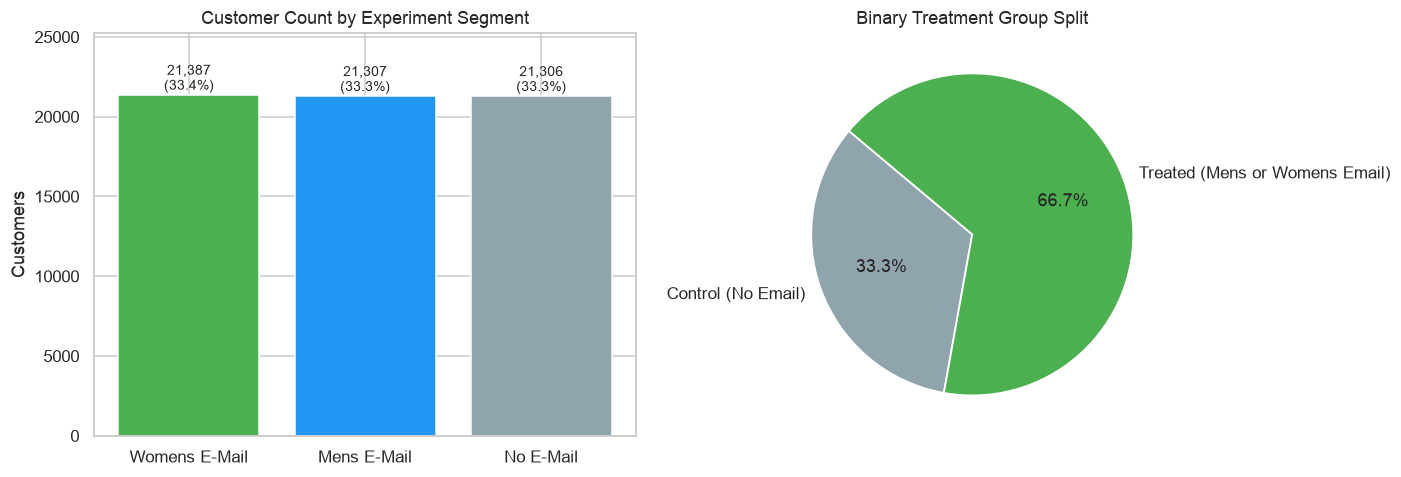

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Segment distribution
seg_counts = df["segment"].value_counts()
colors = ["#4CAF50", "#2196F3", "#90A4AE"]
bars = axes[0].bar(seg_counts.index, seg_counts.values, color=colors, edgecolor="white")
axes[0].set_title("Customer Count by Experiment Segment")
axes[0].set_ylabel("Customers")
for bar in bars:
    h = bar.get_height()
    axes[0].text(
        bar.get_x() + bar.get_width() / 2, h + 300,
        f"{h:,}\n({h/len(df):.1%})", ha="center", fontsize=9
    )
axes[0].set_ylim(0, seg_counts.max() * 1.18)

# Binary treatment split
t_counts = df["treatment"].value_counts().sort_index()
axes[1].pie(
    t_counts.values,
    labels=["Control (No Email)", "Treated (Mens or Womens Email)"],
    autopct="%1.1f%%",
    colors=["#90A4AE", "#4CAF50"],
    startangle=140,
    wedgeprops={"edgecolor": "white", "linewidth": 1.2},
)
axes[1].set_title("Binary Treatment Group Split")

plt.tight_layout()
plt.savefig(f"{FIG_DIR}/01_treatment_distribution.png", bbox_inches="tight")
plt.show()


In [6]:
# One-hot encode categoricals to evaluate balance across all feature levels
df_bal = pd.get_dummies(
    df[["recency", "history", "mens", "womens", "newbie", "zip_code", "channel", "treatment"]],
    columns=["zip_code", "channel"],
    dtype=float,
)

ctrl = df_bal[df_bal["treatment"] == 0].drop(columns="treatment")
trt = df_bal[df_bal["treatment"] == 1].drop(columns="treatment")

balance_rows = []
for col in ctrl.columns:
    m0, m1 = ctrl[col].mean(), trt[col].mean()
    s0, s1 = ctrl[col].std(), trt[col].std()
    pooled_sd = np.sqrt((s0**2 + s1**2) / 2)
    smd = (m1 - m0) / pooled_sd if pooled_sd > 0 else 0.0
    balance_rows.append({
        "Feature": col,
        "Control Mean": m0,
        "Treated Mean": m1,
        "Diff": m1 - m0,
        "SMD": smd,
    })

balance_df = pd.DataFrame(balance_rows)
print("Covariate balance summary:")
print(balance_df.to_string(index=False, float_format=lambda x: f"{x:.4f}"))


Covariate balance summary:
             Feature  Control Mean  Treated Mean    Diff     SMD
             recency        5.7497        5.7707  0.0210  0.0060
             history      240.8827      242.6860  1.8033  0.0071
                mens        0.5532        0.5499 -0.0033 -0.0066
              womens        0.5476        0.5508  0.0031  0.0063
              newbie        0.5020        0.5024  0.0004  0.0008
      zip_code_Rural        0.1473        0.1505  0.0031  0.0088
   zip_code_Suburban        0.4518        0.4486 -0.0032 -0.0064
      zip_code_Urban        0.4009        0.4010  0.0000  0.0001
channel_Multichannel        0.1223        0.1208 -0.0015 -0.0047
       channel_Phone        0.4378        0.4379  0.0001  0.0002
         channel_Web        0.4399        0.4414  0.0015  0.0029


All features have absolute SMD values below 0.01, well under the 0.10 threshold. This confirms the randomization was clean, meaning I do not need to apply propensity score reweighting or confounding corrections.


## 3. Outcome Rates and Average Treatment Effect (ATE)

Next, I examine website visits, conversion, and dollar spend across the test arms.

I calculate the overall average treatment effect on visit rate, construct a 95% confidence interval, and run a Welch's two-sample t-test (equal_var=False) to account for the 2:1 sample size split between the treated and control groups.


In [7]:
# Aggregate outcomes by campaign cell
arm_summary = (
    df.groupby("segment")
    .agg(
        customers=("visit", "count"),
        visit_rate=("visit", "mean"),
        conversion_rate=("conversion", "mean"),
        avg_spend=("spend", "mean"),
        avg_spend_converted=("spend", lambda s: s[s > 0].mean()),
    )
    .reindex(["No E-Mail", "Mens E-Mail", "Womens E-Mail"])
)
print(arm_summary.to_string(float_format=lambda x: f"{x:.4f}"))

# ATE calculation for visit rate
y1 = df.loc[df["treatment"] == 1, "visit"]
y0 = df.loc[df["treatment"] == 0, "visit"]

ate_visit = y1.mean() - y0.mean()
se_ate = np.sqrt(y1.var(ddof=1) / len(y1) + y0.var(ddof=1) / len(y0))
ci_low, ci_high = ate_visit - 1.96 * se_ate, ate_visit + 1.96 * se_ate
t_stat, p_val = stats.ttest_ind(y1, y0, equal_var=False)

print(f"\nOverall ATE (Visit Rate): {ate_visit:+.4f} ({ate_visit*100:+.2f} percentage points)")
print(f"95% Confidence Interval: [{ci_low*100:+.2f} pp, {ci_high*100:+.2f} pp]")
print(f"Welch t-statistic: {t_stat:.2f}, p-value: {p_val:.2e}")


               customers  visit_rate  conversion_rate  avg_spend  avg_spend_converted
segment                                                                              
No E-Mail          21306      0.1062           0.0057     0.6528             114.0027
Mens E-Mail        21307      0.1828           0.0125     1.4226             113.5269
Womens E-Mail      21387      0.1514           0.0088     1.0772             121.8948

Overall ATE (Visit Rate): +0.0609 (+6.09 percentage points)
95% Confidence Interval: [+5.54 pp, +6.63 pp]
Welch t-statistic: 21.92, p-value: 5.09e-106


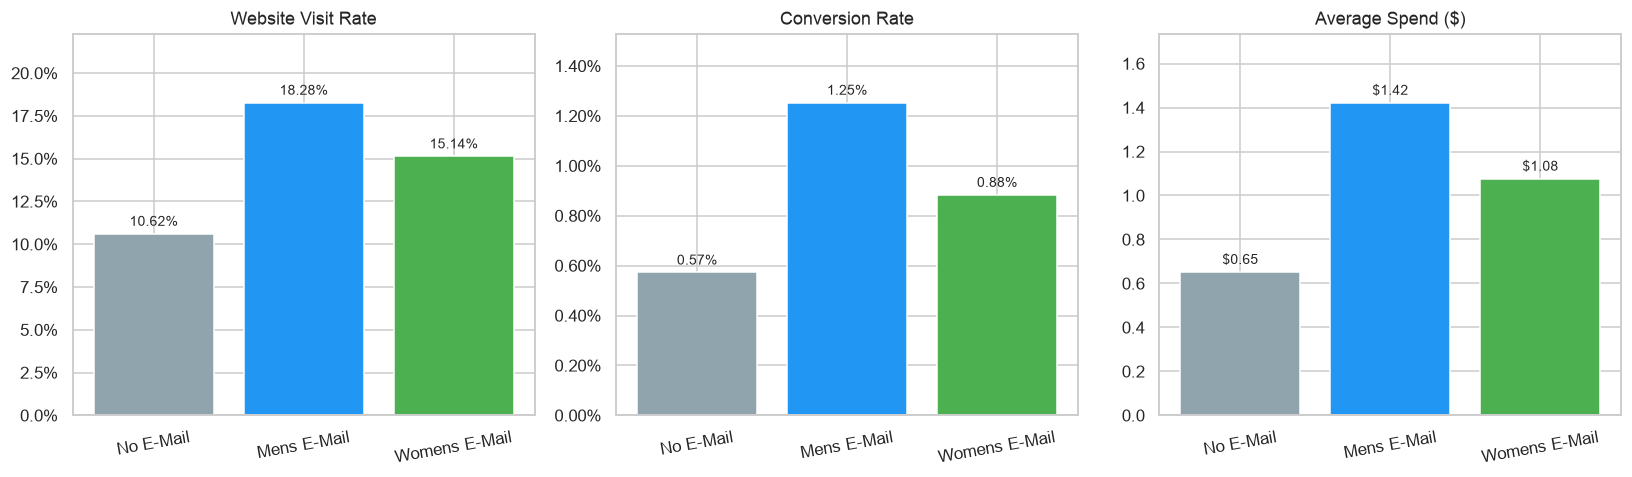

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

metrics = [
    ("visit", "Website Visit Rate", lambda v: f"{v:.2%}", True),
    ("conversion", "Conversion Rate", lambda v: f"{v:.2%}", True),
    ("spend", "Average Spend ($)", lambda v: f"${v:.2f}", False),
]

order = ["No E-Mail", "Mens E-Mail", "Womens E-Mail"]
palette = ["#90A4AE", "#2196F3", "#4CAF50"]

for ax, (col, title, fmt, is_pct) in zip(axes, metrics):
    vals = df.groupby("segment")[col].mean().reindex(order)
    bars = ax.bar(order, vals.values, color=palette, edgecolor="white")
    ax.set_title(title)
    ax.tick_params(axis="x", rotation=10)
    if is_pct:
        ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
    ax.set_ylim(0, vals.max() * 1.22)
    for bar in bars:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width() / 2, h + vals.max() * 0.025, fmt(h), ha="center", fontsize=9)

plt.tight_layout()
plt.savefig(f"{FIG_DIR}/02_conversion_rates.png", bbox_inches="tight")
plt.show()


## 4. Feature Distributions

Here I look at customer recency, historical spend, zip code, and acquisition channel to check distributions and identify any severe skewness.


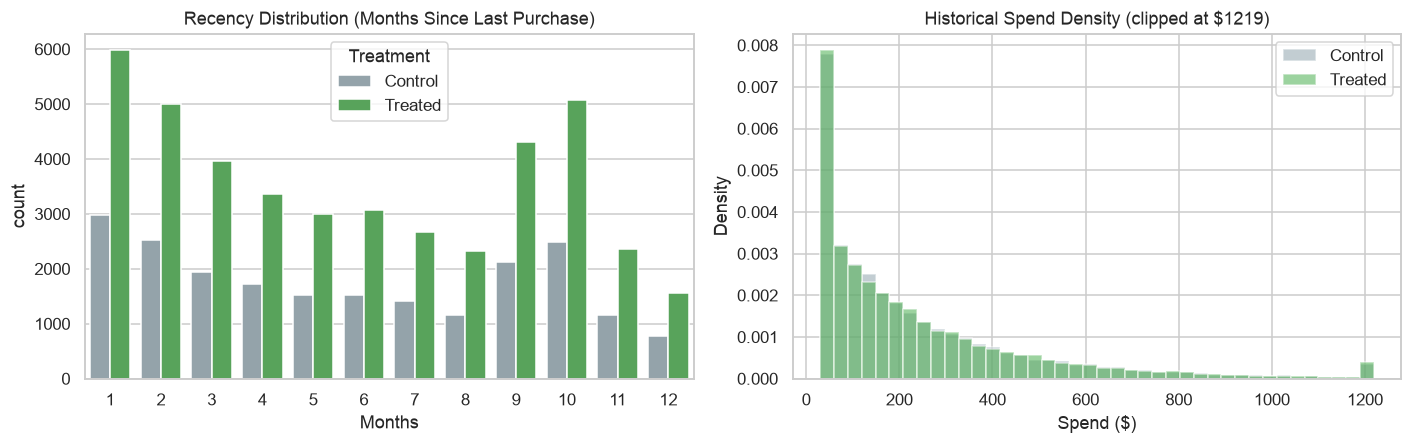

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

# Recency count plot
sns.countplot(data=df, x="recency", hue="treatment", ax=axes[0], palette=["#90A4AE", "#4CAF50"])
axes[0].set_title("Recency Distribution (Months Since Last Purchase)")
axes[0].set_xlabel("Months")
axes[0].legend(title="Treatment", labels=["Control", "Treated"])

# Historical spend density (clipped at 99th percentile to remove extreme tail)
cap = df["history"].quantile(0.99)
for grp, color, lbl in [(0, "#90A4AE", "Control"), (1, "#4CAF50", "Treated")]:
    axes[1].hist(
        df.loc[df["treatment"] == grp, "history"].clip(upper=cap),
        bins=40, alpha=0.55, color=color, label=lbl, density=True, edgecolor="white"
    )
axes[1].set_title(f"Historical Spend Density (clipped at ${cap:.0f})")
axes[1].set_xlabel("Spend ($)")
axes[1].set_ylabel("Density")
axes[1].legend()

plt.tight_layout()
plt.savefig(f"{FIG_DIR}/03_numerical_distributions.png", bbox_inches="tight")
plt.show()


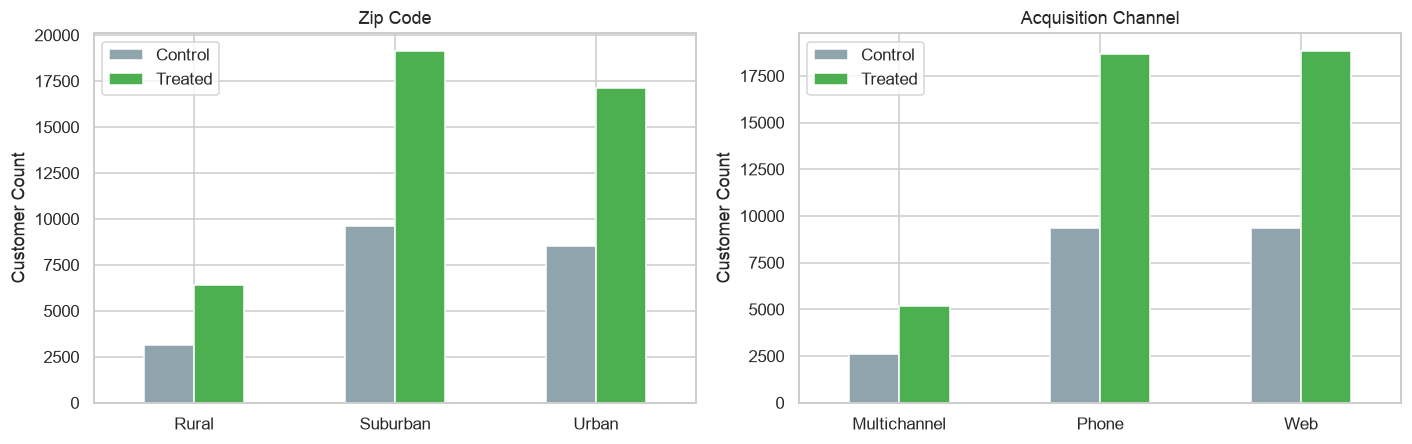

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

for ax, (col, title) in zip(axes, [("zip_code", "Zip Code"), ("channel", "Acquisition Channel")]):
    ct = pd.crosstab(df[col], df["treatment"])
    ct.columns = ["Control", "Treated"]
    ct.plot(kind="bar", ax=ax, color=["#90A4AE", "#4CAF50"], edgecolor="white", rot=0)
    ax.set_title(title)
    ax.set_ylabel("Customer Count")
    ax.set_xlabel("")

plt.tight_layout()
plt.savefig(f"{FIG_DIR}/04_categorical_distributions.png", bbox_inches="tight")
plt.show()


## 5. Heterogeneous Treatment Effects (HTE) Analysis

The population-level ATE shows a +6.09 percentage point lift on visit rate. However, my hypothesis is that email responsiveness varies across customer sub-segments.

Below, I slice the data by customer features, pivot control and treated visit rates side by side, and calculate the sub-group lift:

lift = P(visit | T=1, X) - P(visit | T=0, X)


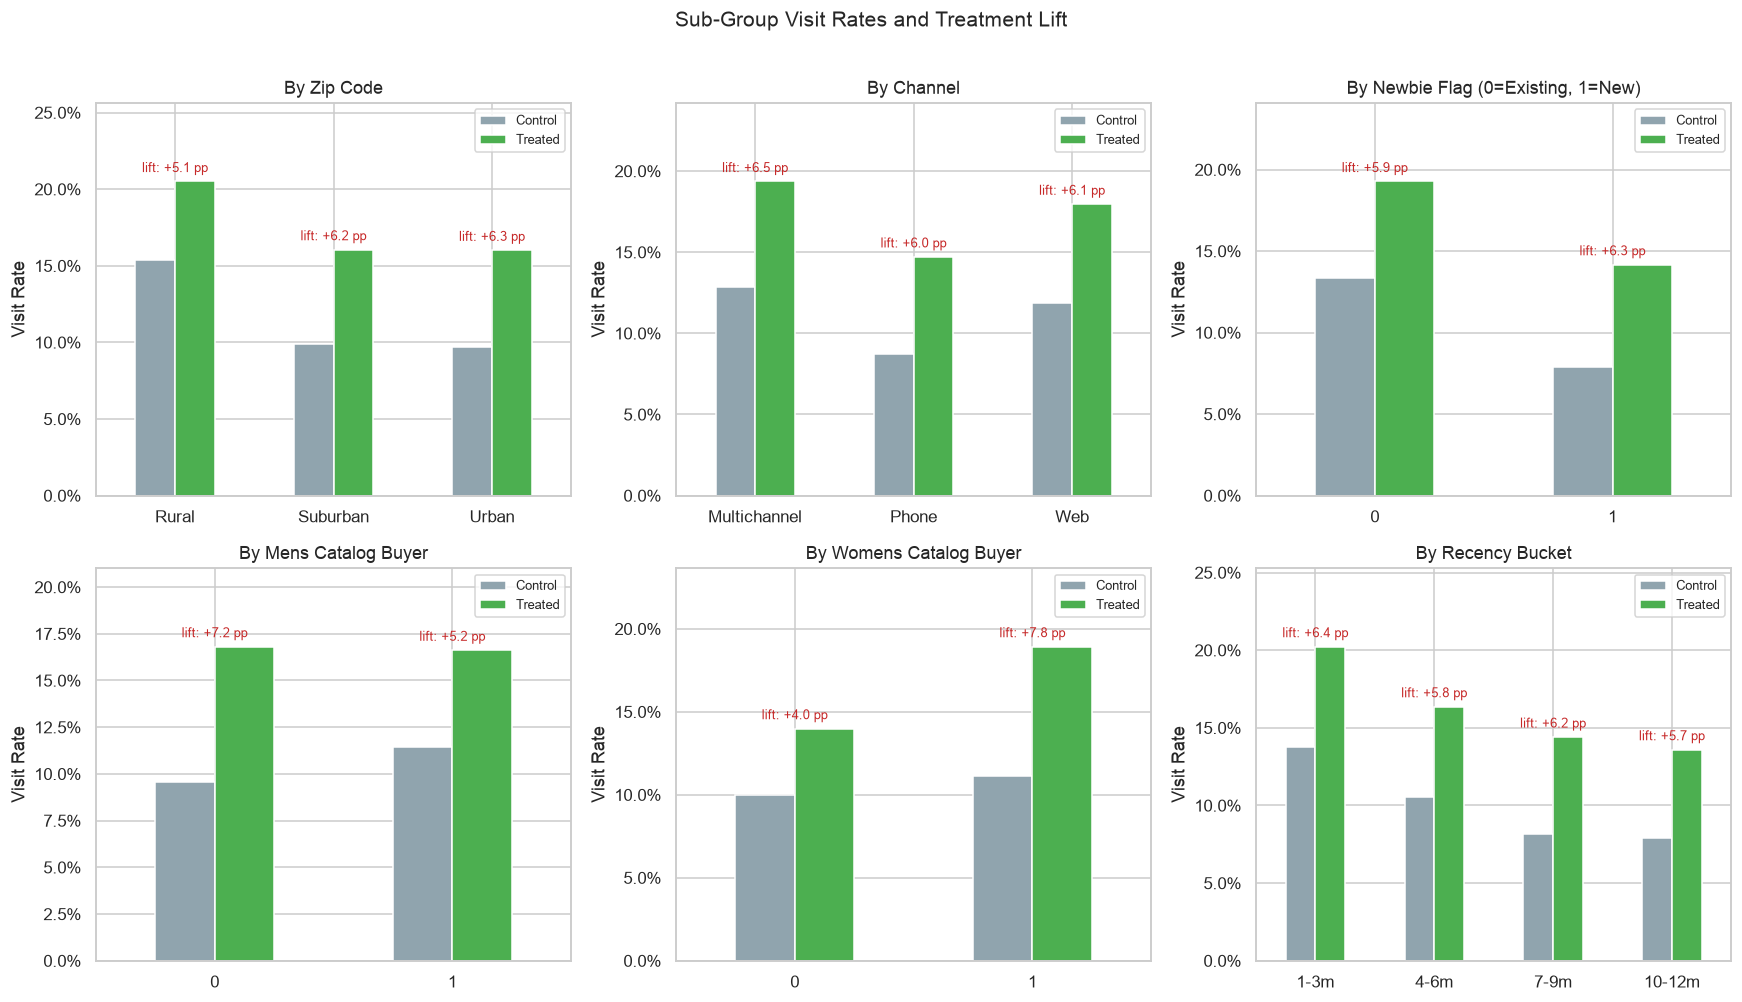

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

# Bin recency into four three-month intervals
df["recency_bucket"] = pd.cut(
    df["recency"], bins=[0, 3, 6, 9, 12], labels=["1-3m", "4-6m", "7-9m", "10-12m"]
)

segments = [
    ("zip_code", "By Zip Code"),
    ("channel", "By Channel"),
    ("newbie", "By Newbie Flag (0=Existing, 1=New)"),
    ("mens", "By Mens Catalog Buyer"),
    ("womens", "By Womens Catalog Buyer"),
    ("recency_bucket", "By Recency Bucket"),
]

for ax, (col, title) in zip(axes, segments):
    grp = df.groupby([col, "treatment"], observed=False)["visit"].mean().unstack()
    grp.columns = ["Control", "Treated"]
    grp["Uplift"] = grp["Treated"] - grp["Control"]

    grp[["Control", "Treated"]].plot(
        kind="bar", ax=ax, color=["#90A4AE", "#4CAF50"], edgecolor="white", rot=0
    )
    ax.set_title(title)
    ax.set_ylabel("Visit Rate")
    ax.set_xlabel("")
    ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
    ax.set_ylim(0, grp[["Control", "Treated"]].values.max() * 1.25)
    ax.legend(fontsize=8.5)

    for i, (_, row) in enumerate(grp.iterrows()):
        y_pos = max(row["Control"], row["Treated"]) + grp[["Control", "Treated"]].values.max() * 0.03
        ax.text(
            i, y_pos, f"lift: {row['Uplift']*100:+.1f} pp",
            ha="center", fontsize=8.5, color="#C62828"
        )

plt.suptitle("Sub-Group Visit Rates and Treatment Lift", fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/05_heterogeneous_effects.png", bbox_inches="tight")
plt.show()


In [12]:
# Check visit rate and lift across historical spend segments
hist_grp = (
    df.groupby(["history_segment", "treatment"])["visit"]
    .mean()
    .unstack()
    .rename(columns={0: "Control", 1: "Treated"})
)
hist_grp["Uplift_pp"] = (hist_grp["Treated"] - hist_grp["Control"]) * 100
hist_grp["Count"] = df.groupby("history_segment").size()

print("Visit rate and lift by historical spend segment:")
print(hist_grp.to_string(float_format=lambda x: f"{x:.4f}" if x < 1 else f"{x:.2f}"))


Visit rate and lift by historical spend segment:
treatment         Control  Treated  Uplift_pp  Count
history_segment                                     
1) $0 - $100       0.0849   0.1426       5.77  22970
2) $100 - $200     0.0910   0.1467       5.58  14254
3) $200 - $350     0.1264   0.1864       6.01  12289
4) $350 - $500     0.1502   0.2145       6.43   6409
5) $500 - $750     0.1096   0.1918       8.22   4911
6) $750 - $1,000   0.1543   0.2126       5.83   1859
7) $1,000 +        0.1659   0.2422       7.63   1308


## 6. Correlation Structure


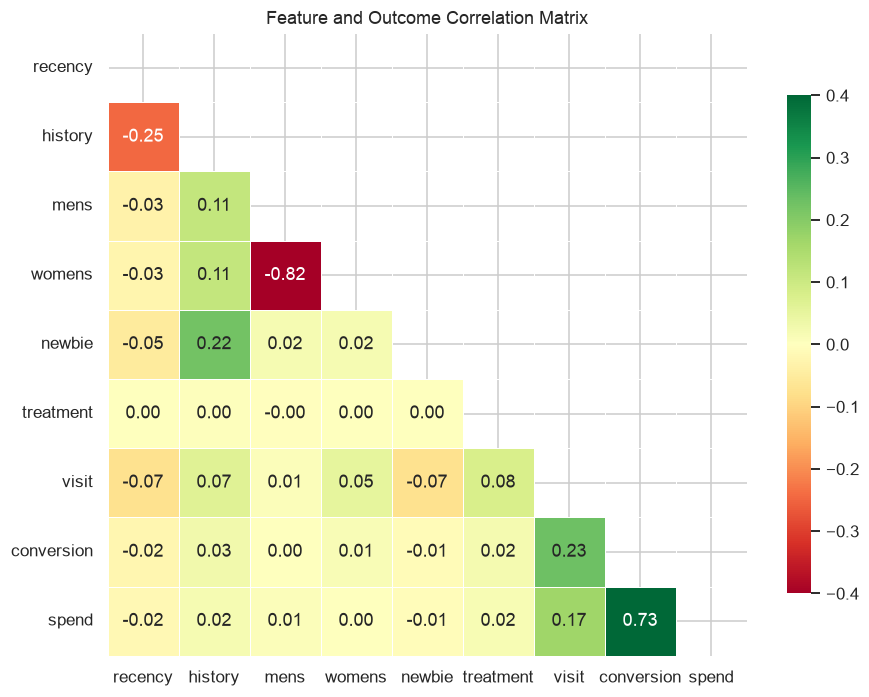

In [13]:
num_cols = ["recency", "history", "mens", "womens", "newbie", "treatment", "visit", "conversion", "spend"]
corr = df[num_cols].corr()

fig, ax = plt.subplots(figsize=(8.5, 6.5))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(
    corr, mask=mask, annot=True, fmt=".2f", cmap="RdYlGn",
    center=0, vmin=-0.4, vmax=0.4, linewidths=0.5, ax=ax,
    cbar_kws={"shrink": 0.8},
)
ax.set_title("Feature and Outcome Correlation Matrix")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/06_correlation_matrix.png", bbox_inches="tight")
plt.show()


## 7. Key Findings & Next Steps

1. Clean Randomization: Pre-treatment covariates have near-zero standardized mean differences (|SMD| < 0.01) between treatment and control cohorts. This confirms the experiment was cleanly randomized, allowing me to train response models without observational bias corrections.
2. Typos in Raw Data: The raw file spells Suburban as Surburban. My preprocessing pipeline maps this properly to ensure records are not dropped or misclassified during inference.
3. Treatment Effect Size: Overall visit rate increases from 10.62% in control to 16.71% in treated (+6.09 percentage points, Welch t = 21.92, p < 1e-100).
4. Treatment Heterogeneity:
   - Past buyers of the womens catalog show a +7.78 pp lift compared to +4.00 pp for non-buyers.
   - Customers with higher historical spend ($500+) show larger incremental lifts than lower spenders ($0-$100).
   - Recent purchasers (1-3 months) have higher baseline visit rates and strong response to the campaign.
5. Implications for Uplift Modeling: Because customer response is heterogeneous, targeting the entire customer base is inefficient. In Phase 2, I build meta-learners (S-Learner and T-Learner) to estimate individual treatment effects (ITE) and optimize intervention policy based on expected uplift.
